# Leave-one-dataset-out (LODO) classification — 5 RenoRisk genes panel

Plan §6. Each fold trains on all cohorts but one and predicts the left-out cohort; every cohort is
an unseen test set exactly once. There is no separate hold-out set.

- **Input:** `Data/ML_input/all.xlsx` (1322 samples, 19 series: 14 microarray + 5 RNA-Seq; 1077 Disease /
  245 Control). Expression values are as deposited or submitter-normalised (uncorrected; several value
  scales — log2 arrays, per-gene-centred arrays, RNA-Seq log2 / log2-CPM; see CLAUDE.md) — part of what
  LODO tests is whether a model survives that.
- **Missing values:** C4BPA is NA for GSE142025 and GSE137570 (60 rows; not in those RNA-Seq deposits).
  The pipeline's mean imputation fills it from the training cohorts of each fold (PyCaret default).
- **Features:** the 5 RenoRisk gene expressions plus `Compartment` and `Sex`; one LODO run, no feature selection.
- **Groups (17 LODO cohorts):** `StudyID`, each dataset as it is (GSE104948 and GSE104954, the two ERCB
  compartments, are separate cohorts — by instruction, 2026-11-04; they may share biopsies, which GEO cannot
  confirm, so their held-out scores may be optimistic); only GSE108109 +
  GSE200828 + GSE219185 merged into one NEPTUNE cohort (`MERGE_NEPTUNE`): GSE200828 reuses 96 GSE108109
  samples (`Results/SampleOverlap`) and GSE219185 is the tubulointerstitium of NEPTUNE patients whose glomeruli
  are in GSE108109. GSE137570 (24 CKD) is a cohort with no controls: its F1 / precision / recall / accuracy
  are computed, its ROC-AUC is undefined and left out of the mean ROC-AUC and the mean ROC curve.
- **`Platform`** (Microarray / RNA-Seq) is never a feature: it is confounded with study.
- **Models:** all 17 standalone classifiers in PyCaret 3.3.2's model library, with PyCaret's default
  arguments (`random_state=42`). `compare_models()` runs 14 of them by default; RBF SVM, Gaussian
  process and MLP are its `turbo=False` models. XGBoost and CatBoost are not installed. PyCaret's
  meta-estimators (bagging, stacking, voting, calibration) wrap other models and are not included.
- **Preprocessing** mirrors PyCaret's defaults — numeric mean imputation, categorical mode imputation,
  one-hot encoding, no scaling — and sits inside the `Pipeline`, so it is fitted on the training
  cohorts of each fold only. No model is selected on these scores.
- **Metrics:** F1, precision, recall, accuracy and ROC-AUC, each computed on every left-out cohort and
  then averaged (unweighted) over the 17 cohorts — the same convention as PyCaret's `compare_models`,
  which averages over folds. Positive class = Disease; labels from `predict()`, scores from
  `predict_proba()` or, for ridge and linear SVM, `decision_function()`. The report is sorted by ROC-AUC.
- **Why not pool the predictions for ROC-AUC:** each fold's model is trained on a different mix of
  cohorts, so its score level shifts from fold to fold and a pooled ROC mostly ranks those shifts —
  the prior-only dummy would get ROC-AUC ≈ 0.19 instead of 0.5.
- **F1 rewards predicting "Disease":** ~80% of samples are Disease, so the dummy model that always
  predicts it scores a high F1. Compare every model against the dummy row, and read ROC-AUC alongside.

In [11]:
import sys, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import lightgbm
from lightgbm import LGBMClassifier
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (AdaBoostClassifier, ExtraTreesClassifier, GradientBoostingClassifier,
                              RandomForestClassifier)
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, roc_curve
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
MERGE_NEPTUNE = True       # GSE108109 + GSE200828 + GSE219185 -> one LODO group (shared NEPTUNE patients)

DATA_PATH = Path('../Data/ML_input/all.xlsx')
OUT_DIR = Path('../Results/ML_training/RR')
OUT_DIR.mkdir(parents=True, exist_ok=True)

GENES = ['C4BPA', 'COL13A1', 'HABP2', 'CFH', 'CFI']
CATEGORICAL = ['Compartment', 'Sex']
TARGET = 'Disease_Label'

In [12]:
df = pd.read_excel(DATA_PATH)

# NEPTUNE: GSE200828 reuses 96 GSE108109 samples (Results/SampleOverlap); GSE219185 is the tubulointerstitium
# of NEPTUNE patients whose glomeruli are in GSE108109. Held out together, so no patient is on both sides of a fold.
NEPTUNE = {'GSE108109', 'GSE200828', 'GSE219185'}
df['Cohort'] = np.where(MERGE_NEPTUNE & df['StudyID'].isin(NEPTUNE), 'NEPTUNE', df['StudyID'])

X = df[GENES + CATEGORICAL]
y = df[TARGET].to_numpy()
groups = df['Cohort'].to_numpy()

print(df.shape, '| folds:', df['Cohort'].nunique())
pd.crosstab(df['Cohort'], df[TARGET], margins=True)

(850, 14) | folds: 10


Disease_Label,0,1,All
Cohort,,,
ERCB,42,89,131
GSE108109,6,105,111
GSE116626,7,74,81
GSE121233,5,5,10
GSE129973,20,20,40
GSE200828,6,147,153
GSE30122,50,19,69
GSE66494,8,53,61
GSE96804,20,41,61


In [13]:
def make_pipeline(model, genes, categorical):
    # PyCaret defaults: mean / mode imputation, one-hot encoding, no normalisation
    num = [('num', SimpleImputer(strategy='mean'), genes)] if genes else []
    cat = [('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                             ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical)] if categorical else []
    return Pipeline([('pre', ColumnTransformer(num + cat)), ('model', clone(model))])

RS = RANDOM_STATE
# PyCaret 3.3.2 model library: ID -> (name, estimator with PyCaret's default args, in compare_models turbo)
PYCARET_MODELS = {
    'lr':       ('Logistic Regression', LogisticRegression(max_iter=1000, random_state=RS), True),
    'knn':      ('K Neighbors Classifier', KNeighborsClassifier(n_jobs=-1), True),
    'nb':       ('Naive Bayes', GaussianNB(), True),
    'dt':       ('Decision Tree Classifier', DecisionTreeClassifier(random_state=RS), True),
    'svm':      ('SVM - Linear Kernel', SGDClassifier(tol=0.001, loss='hinge', penalty='l2', eta0=0.001,
                                                      random_state=RS, n_jobs=-1), True),
    'rbfsvm':   ('SVM - Radial Kernel', SVC(gamma='auto', C=1.0, probability=True, kernel='rbf',
                                            random_state=RS), False),
    'gpc':      ('Gaussian Process Classifier', GaussianProcessClassifier(copy_X_train=False, random_state=RS,
                                                                          n_jobs=-1), False),
    'mlp':      ('MLP Classifier', MLPClassifier(random_state=RS, max_iter=500), False),
    'ridge':    ('Ridge Classifier', RidgeClassifier(random_state=RS), True),
    'rf':       ('Random Forest Classifier', RandomForestClassifier(random_state=RS, n_jobs=-1), True),
    'qda':      ('Quadratic Discriminant Analysis', QuadraticDiscriminantAnalysis(), True),
    'ada':      ('Ada Boost Classifier', AdaBoostClassifier(random_state=RS), True),
    'gbc':      ('Gradient Boosting Classifier', GradientBoostingClassifier(random_state=RS), True),
    'lda':      ('Linear Discriminant Analysis', LinearDiscriminantAnalysis(), True),
    'et':       ('Extra Trees Classifier', ExtraTreesClassifier(random_state=RS, n_jobs=-1), True),
    'lightgbm': ('Light Gradient Boosting Machine', LGBMClassifier(random_state=RS, n_jobs=-1, verbose=-1), True),
    'dummy':    ('Dummy Classifier', DummyClassifier(strategy='prior', random_state=RS), True),
}

In [14]:
def positive_score(pipe, X_test):
    """Score for the Disease class: probability when available, else the decision function."""
    if hasattr(pipe, 'predict_proba'):
        return pipe.predict_proba(X_test)[:, 1]
    return pipe.decision_function(X_test)

def lodo(genes, categorical):
    """LODO: one fold per cohort; every sample gets exactly one out-of-fold prediction per model."""
    X = df[genes + categorical]
    logo = LeaveOneGroupOut()
    oof = []
    with warnings.catch_warnings():
        # expected on these data: QDA collinearity (one-hot columns), SAMME.R deprecation in AdaBoost
        warnings.filterwarnings('ignore', category=UserWarning)
        warnings.filterwarnings('ignore', category=FutureWarning)
        for i, (mid, (name, est, _)) in enumerate(PYCARET_MODELS.items(), 1):
            print(f'[{i}/{len(PYCARET_MODELS)}] Training {name} ({mid})', flush=True)
            pipe = make_pipeline(est, genes, categorical)
            for train_idx, test_idx in logo.split(X, y, groups):
                held_out = np.unique(groups[test_idx])
                assert len(held_out) == 1 and held_out[0] not in set(groups[train_idx])
                pipe.fit(X.iloc[train_idx], y[train_idx])
                X_test = X.iloc[test_idx]
                oof.append(pd.DataFrame({'Model_ID': mid, 'Cohort': held_out[0],
                                         'GSM': df['GSM'].iloc[test_idx].to_numpy(), 'y_true': y[test_idx],
                                         'score': positive_score(pipe, X_test), 'y_pred': pipe.predict(X_test)}))
    oof = pd.concat(oof, ignore_index=True)
    assert (oof.groupby('Model_ID').size() == len(df)).all()
    assert not oof.duplicated(['Model_ID', 'GSM']).any()
    return oof

In [15]:
def metrics(d):
    return {'F1': f1_score(d['y_true'], d['y_pred'], zero_division=0),
            'Precision': precision_score(d['y_true'], d['y_pred'], zero_division=0),
            'Recall': recall_score(d['y_true'], d['y_pred'], zero_division=0),
            'Accuracy': accuracy_score(d['y_true'], d['y_pred']),
            'ROC-AUC': roc_auc_score(d['y_true'], d['score']) if d['y_true'].nunique() == 2 else np.nan}

METRICS = ['F1', 'Precision', 'Recall', 'Accuracy', 'ROC-AUC']

def lodo_metrics(oof):
    per_cohort = pd.DataFrame([{'Model_ID': mid, 'Cohort': c, 'n': len(d),
                                'n_control': int((d['y_true'] == 0).sum()), 'n_disease': int((d['y_true'] == 1).sum()),
                                **metrics(d)}
                               for (mid, c), d in oof.groupby(['Model_ID', 'Cohort'], sort=False)])

    # One value per metric per model: mean over the left-out cohorts (as PyCaret averages over folds)
    means = per_cohort.groupby('Model_ID', sort=False)[METRICS].mean()
    summary = pd.DataFrame({
        'Model': [PYCARET_MODELS[m][0] for m in means.index],
        'PyCaret ID': means.index,
        'In compare_models (turbo)': [PYCARET_MODELS[m][2] for m in means.index],
        **{m: means[m].to_numpy() for m in METRICS}})
    summary = summary.sort_values('ROC-AUC', ascending=False, ignore_index=True, kind='stable')
    return per_cohort, summary

In [16]:
import textwrap

def plot_best_roc(oof, per_cohort, summary, features, out_dir, by='F1'):
    # Mean ROC curve of the best model by mean `by` (F1 or ROC-AUC; the dummy baseline excluded): the per-cohort
    # curves averaged vertically at fixed false positive rates. Predictions are not pooled across folds - each
    # fold's model has its own score scale.
    ranked = summary[summary['PyCaret ID'] != 'dummy'].sort_values(by, ascending=False, kind='stable')
    best_id = ranked['PyCaret ID'].iloc[0]
    best_f1, best_auc = ranked[['F1', 'ROC-AUC']].iloc[0]
    fpr_grid = np.linspace(0, 1, 201)
    tprs, aucs, skipped = [], [], []
    for cohort, d in oof[oof['Model_ID'] == best_id].groupby('Cohort', sort=False):
        if d['y_true'].nunique() < 2:            # ROC undefined with one class
            skipped.append(cohort)
            continue
        fpr, tpr, _ = roc_curve(d['y_true'], d['score'])
        tpr_grid = np.interp(fpr_grid, fpr, tpr)
        tpr_grid[0] = 0.0
        tprs.append(tpr_grid)
        aucs.append(roc_auc_score(d['y_true'], d['score']))
    tpr_mean = np.mean(tprs, axis=0)
    tpr_mean[-1] = 1.0

    fig, ax = plt.subplots(figsize=(9, 10.5))   # larger canvas for the doubled font sizes
    ax.plot(fpr_grid, tpr_mean, lw=2.5, color='#0000FF',
            label=f'Mean of {len(aucs)} left-out cohorts: AUC {np.mean(aucs):.2f}')
    ax.plot([0, 1], [0, 1], ls='--', lw=1, color='grey', label='Chance')
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.01); ax.set_aspect('equal')
    ax.set_xlabel('False positive rate (1 - specificity)', fontsize=20)
    ax.set_ylabel('True positive rate (sensitivity)', fontsize=20)
    ax.tick_params(labelsize=20)
    ax.set_title(f'LODO, {features}\nmean ROC of the best model by {by}:\n'
                 f'{PYCARET_MODELS[best_id][0]} ({best_id})\n'
                 f'mean F1 {best_f1:.3f}, mean ROC-AUC {best_auc:.3f}', fontsize=20)
    ax.legend(fontsize=16, loc='lower right')
    note = 'Average of the per-cohort ROC curves; each cohort scored by the model trained on the others.'
    if skipped:
        note += f' Not included (one class only): {", ".join(skipped)}.'
    fig.text(0.01, 0.005, textwrap.fill(note, 85), fontsize=14, color='grey')
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    fig.savefig(out_dir / f"ML_RR_AUC_by_{by.replace('ROC-AUC', 'AUC')}.png", dpi=200)
    plt.show()

In [17]:
# Feature importances of the best model by F1 and by ROC-AUC (dummy excluded, as for the ROC figures), refitted on
# all samples (as PyCaret does after compare_models). These show what the model relies on when trained on every cohort;
# LODO validates the model, not this ranking.
# - Native where the model has them, one row per model input (each one-hot column separately): |coefficient| for
#   linear models (inputs are not scaled, so sizes also follow each gene's value scale; the signed Coefficient is kept,
#   > 0 pushes towards Disease), feature_importances_ for trees / boosting.
# - Otherwise permutation importance: mean drop in ROC-AUC when one input column is shuffled (5 repeats), on the
#   samples the model was fitted on.
NATIVE_IMPORTANCE = ['lr', 'svm', 'ridge', 'lda', 'dt', 'rf', 'et', 'ada', 'gbc', 'lightgbm']

def best_model_importances(summary, genes, categorical, by):
    ranked = summary[summary['PyCaret ID'] != 'dummy'].sort_values(by, ascending=False, kind='stable')
    best_id = ranked['PyCaret ID'].iloc[0]
    X_all = df[genes + categorical]
    pipe = make_pipeline(PYCARET_MODELS[best_id][1], genes, categorical).fit(X_all, y)
    model = pipe.named_steps['model']
    if best_id in NATIVE_IMPORTANCE:
        kind, features = zip(*(name.split('__', 1) for name in pipe.named_steps['pre'].get_feature_names_out()))
        # Source = the input column a feature comes from (a one-hot column maps back to Compartment / Sex)
        source = [f if k == 'num' else next(c for c in categorical if f.startswith(c + '_'))
                  for k, f in zip(kind, features)]
        if hasattr(model, 'coef_'):
            coef = np.ravel(model.coef_)
            imp = pd.DataFrame({'Feature': features, 'Source': source, 'Importance': np.abs(coef), 'Coefficient': coef})
            method = '|coefficient|'
        else:
            imp = pd.DataFrame({'Feature': features, 'Source': source, 'Importance': model.feature_importances_})
            method = 'feature_importances_'
    else:
        with warnings.catch_warnings():
            warnings.filterwarnings('ignore', category=UserWarning)
            perm = permutation_importance(pipe, X_all, y, scoring='roc_auc', n_repeats=5,
                                          random_state=RANDOM_STATE, n_jobs=-1)
        imp = pd.DataFrame({'Feature': genes + categorical, 'Source': genes + categorical,
                            'Importance': perm.importances_mean})
        method = 'permutation (mean ROC-AUC drop)'
    imp = imp.sort_values('Importance', ascending=False, ignore_index=True, kind='stable')
    imp.insert(0, 'Rank', np.arange(1, len(imp) + 1))
    head = {'Selected by': by, 'Model': PYCARET_MODELS[best_id][0], 'PyCaret ID': best_id, 'Importance method': method}
    return pd.concat([pd.DataFrame(head, index=imp.index), imp], axis=1)

def report_importances(summary, genes, categorical, out_dir, prefix, n_print=None):
    """Print the importances of the best model by F1 and by ROC-AUC; one file each, <prefix>_FEAT_IMP_by_F1.xlsx / _by_AUC.xlsx."""
    for by in ['F1', 'ROC-AUC']:
        imp = best_model_importances(summary, genes, categorical, by)
        imp[[c for c in ['Source', 'Importance', 'Coefficient'] if c in imp]].to_excel(
            out_dir / f"{prefix}_FEAT_IMP_by_{by.replace('ROC-AUC', 'AUC')}.xlsx", index=False)
        first = imp.iloc[0]
        shown = imp if n_print is None else imp.head(n_print)
        print(f"\n=== Best model by {by}: {first['Model']} ({first['PyCaret ID']}); importance = {first['Importance method']}"
              + ('' if n_print is None or n_print >= len(imp) else f'; top {n_print:,} of {len(imp):,} shown') + ' ===')
        cols = ['Rank', 'Feature', 'Importance'] + (['Coefficient'] if 'Coefficient' in imp else [])
        print(shown[cols].to_string(index=False, float_format=lambda v: f'{v:.4g}'))


In [18]:
def write_session_info(out_dir, genes, categorical):
    # Provenance next to the outputs (project convention): versions, settings, models, input
    with open(out_dir / 'ML_RR_sessionInfo.txt', 'w') as fh:
        fh.write(f'python {sys.version}\nplatform {platform.platform()}\n')
        fh.write(f'scikit-learn {sklearn.__version__}\nlightgbm {lightgbm.__version__}\n'
                 f'pandas {pd.__version__}\nnumpy {np.__version__}\n')
        fh.write(f'RANDOM_STATE={RANDOM_STATE} MERGE_NEPTUNE={MERGE_NEPTUNE}\n')
        fh.write(f'models (PyCaret 3.3.2 defaults): {", ".join(PYCARET_MODELS)}\n')
        fh.write(f'input {DATA_PATH.resolve()} ({len(df)} samples, {len(genes)} genes + {categorical}, '
                 f'{df["Cohort"].nunique()} LODO groups)\n')

=== LODO on 5 RenoRisk genes + ['Compartment', 'Sex'] ===
[1/17] Training Logistic Regression (lr)
[2/17] Training K Neighbors Classifier (knn)
[3/17] Training Naive Bayes (nb)
[4/17] Training Decision Tree Classifier (dt)
[5/17] Training SVM - Linear Kernel (svm)
[6/17] Training SVM - Radial Kernel (rbfsvm)
[7/17] Training Gaussian Process Classifier (gpc)
[8/17] Training MLP Classifier (mlp)
[9/17] Training Ridge Classifier (ridge)
[10/17] Training Random Forest Classifier (rf)
[11/17] Training Quadratic Discriminant Analysis (qda)
[12/17] Training Ada Boost Classifier (ada)
[13/17] Training Gradient Boosting Classifier (gbc)
[14/17] Training Linear Discriminant Analysis (lda)
[15/17] Training Extra Trees Classifier (et)
[16/17] Training Light Gradient Boosting Machine (lightgbm)
[17/17] Training Dummy Classifier (dummy)


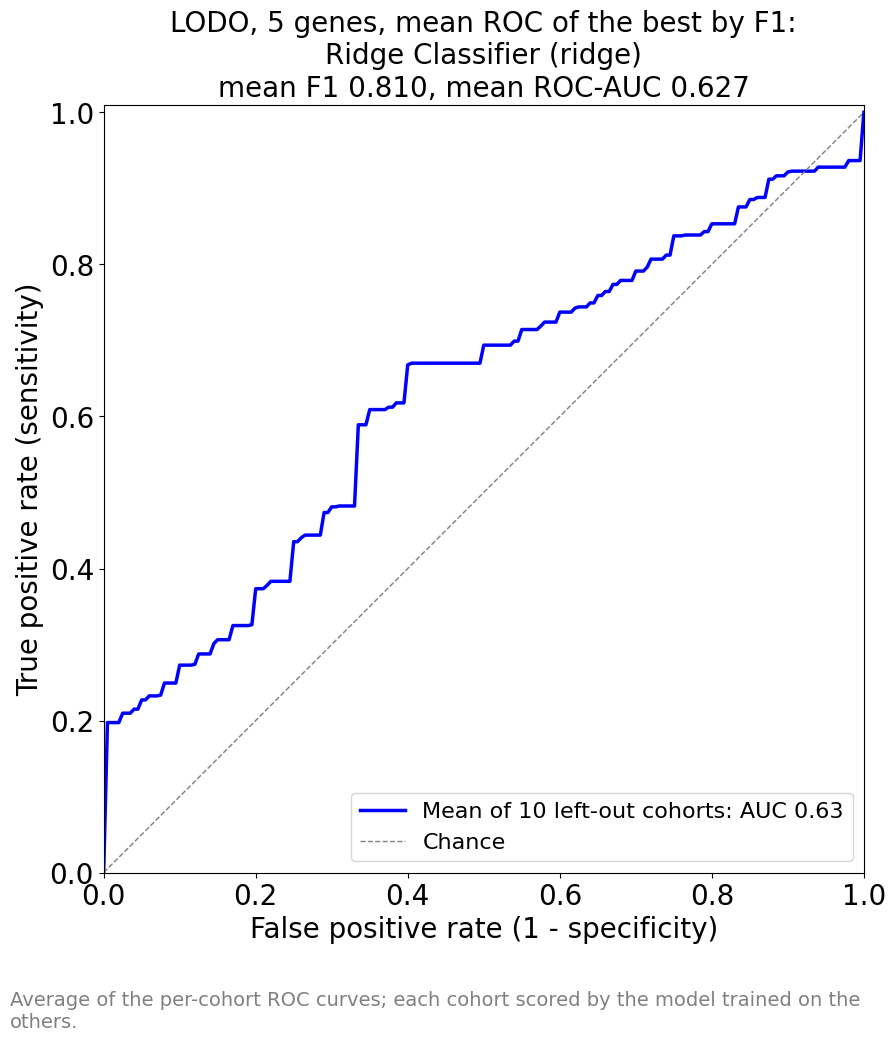

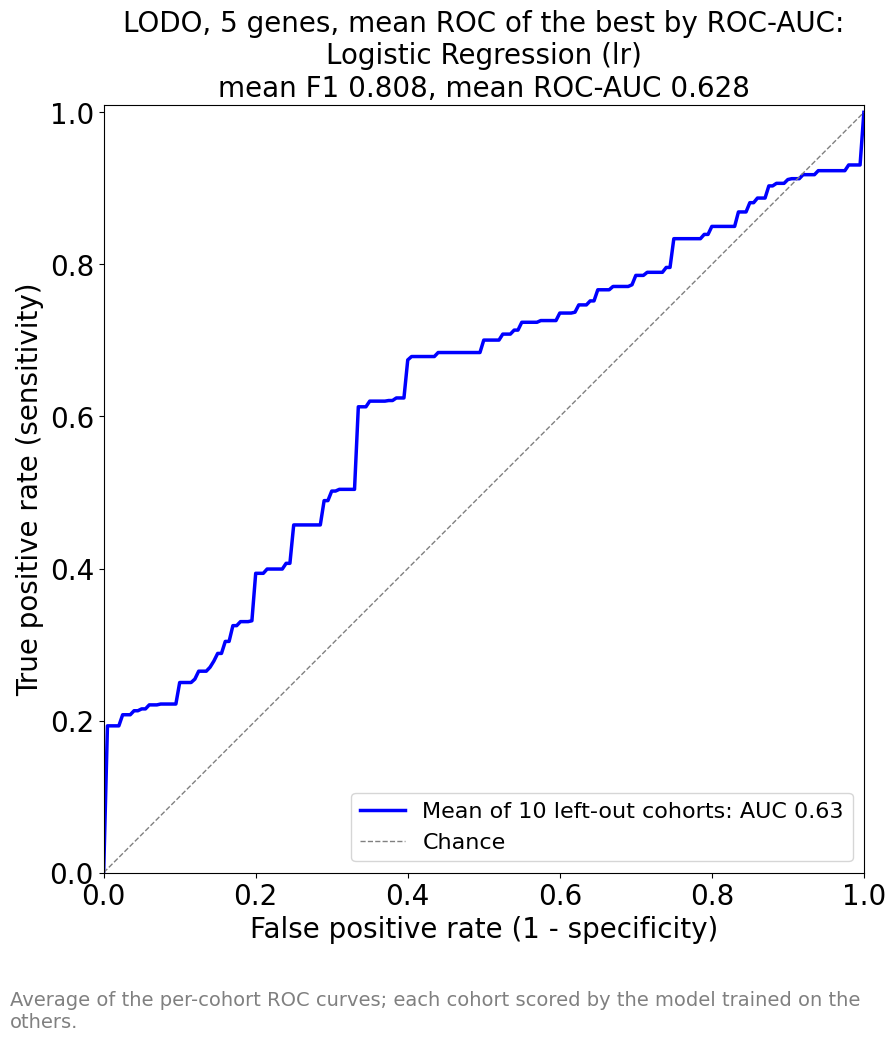

                          Model PyCaret ID    F1  Precision  Recall  Accuracy  ROC-AUC
            Logistic Regression         lr 0.808      0.727   0.973     0.711    0.628
               Ridge Classifier      ridge 0.810      0.731   0.972     0.721    0.627
   Linear Discriminant Analysis        lda 0.800      0.730   0.954     0.709    0.626
            SVM - Radial Kernel     rbfsvm 0.767      0.741   0.904     0.675    0.604
         K Neighbors Classifier        knn 0.719      0.737   0.831     0.631    0.595
    Gaussian Process Classifier        gpc 0.722      0.742   0.842     0.638    0.586
         Extra Trees Classifier         et 0.731      0.718   0.821     0.654    0.581
                    Naive Bayes         nb 0.677      0.640   0.810     0.590    0.553
Light Gradient Boosting Machine   lightgbm 0.710      0.731   0.773     0.623    0.550
       Random Forest Classifier         rf 0.706      0.713   0.802     0.646    0.550
                 MLP Classifier        mlp 

In [19]:
def run(genes, categorical, out_dir):
    """LODO over the PyCaret models: performance table, the two ROC figures, best-model feature importances and provenance, in out_dir."""
    out_dir.mkdir(parents=True, exist_ok=True)
    oof = lodo(genes, categorical)
    features = f"{len(genes)} RenoRisk genes + {', '.join(categorical)}"   # ROC figure title
    per_cohort, summary = lodo_metrics(oof)
    for by in ['F1', 'ROC-AUC']:
        plot_best_roc(oof, per_cohort, summary, features, out_dir, by)
    # LODO performance per classifier (mean over the left-out cohorts), sorted by ROC-AUC; the printed table also as .xlsx
    perfs = summary[['Model', 'PyCaret ID'] + METRICS].round(3)
    perfs.to_excel(out_dir / 'ML_RR_perfs.xlsx', index=False)
    print(perfs.to_string(index=False))
    report_importances(summary, genes, categorical, out_dir, 'ML_RR')
    write_session_info(out_dir, genes, categorical)
    return summary, per_cohort

# The 5 RenoRisk genes + Compartment + Sex
print(f'=== LODO on {len(GENES)} RenoRisk genes + {CATEGORICAL} ===')
summary, per_cohort = run(GENES, CATEGORICAL, OUT_DIR)